# Exercise 02 · Transformers from Scratch

**Advanced Methods to Machine Learning** · WiSe 2026/27 · Exercise session Thu 29.10.2026

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Moritz-Wirth/advanced-ml-exercises/blob/main/exercises/02_transformer/transformer_exercise.ipynb)

In the lecture, self-attention was derived step by step: from a plain weighted sum, through query, key and value,
to multi-head attention, positional encoding and the full Transformer block. In this notebook you **build each of
these pieces yourself in PyTorch**, check it against PyTorch's own implementation, and finally **train a tiny
Transformer encoder** on a toy bird-song task where order is everything.

| Section | Topic | Slides | Time |
|---|---|---|---|
| 1 | Softmax and the $\sqrt{d_k}$ scaling | 27, 35 | ⏱ ~8 min |
| 2 | Scaled dot-product attention | 26–34 | ⏱ ~15 min |
| 3 | Masks | 36, 65 | ⏱ ~8 min |
| 4 | 🔜 Multi-head attention | 42–44 | ⏱ ~10 min |
| 5 | 🔜 Positional encoding | 46–53 | ⏱ ~12 min |
| 6 | 🔜 The Transformer block | 55–60 | ⏱ ~8 min |
| 7 | Train a tiny Transformer: who sang this? | Intro 19 | ⏱ ~12 min |
| ⭐ | Stretch: RoPE, the FFN, real attention in DistilBERT, ablations | 18, 25, 53, 61 | at home |

Sections 1–3 build on what the lecture has covered so far. Sections 4–6 (🔜) come **ahead of the lecture**: they
are covered in the next lecture, and the notebook explains everything you need for them. In the exercise session
we start them with a short introduction.

### How to work with this notebook

- **Run the setup cell below first.** It needs no installs and no GPU; everything runs on a CPU in seconds.
- `raise NotImplementedError  # TODO` marks **your code**. Replace that line with your implementation.
- Each gap is followed by a **check cell**. ✅ means you are good to go; ❌ tells you what is wrong and which slide to revisit.
- 🧠 **Predict first**: write down your guess *before* running the cell. Being surprised is where the learning happens.
- ✍️ **Questions**: answer in one to three sentences. They are close to what the oral exam asks.
- Inside your solutions, do **not** use `F.scaled_dot_product_attention`, `nn.MultiheadAttention` or
  `nn.TransformerEncoderLayer`. The checks use them as a reference.
- Slide numbers refer to the **Transformer lecture** (number bottom right). "Intro slide" refers to the course introduction.

### Notation (as in the lecture)

| Symbol | Meaning |
|---|---|
| $n$ | sequence length (number of tokens) |
| $d$ (`d_model`) | embedding dimension |
| $d_k$, $d_v$ | dimension of queries/keys and of values (per head) |
| $h$ | number of heads |
| $X \in \mathbb{R}^{n \times d}$ | input sequence, **one token per row** |

In code, tensors carry an extra batch dimension in front: `(B, n, d)`.

In [1]:
#@title ⚙️ Setup: run this cell first (you do not need to read it)

# ---- common/helpers.py -----------------------------------------------------

# Shared helpers for all exercise notebooks of the course.
#
# This file is the master copy. scripts/build.py pastes it into the hidden
# setup cell of every notebook, so students never install anything.
# Rules: standard Colab packages only, and no exercise solutions in here.

import math
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
np.random.seed(0)
torch.set_printoptions(precision=3, sci_mode=False)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})


class CheckFailed(Exception):
    """Raised by the check functions. Rendered as a short message instead of a traceback."""

    def _render_traceback_(self):  # IPython / Colab hook
        return [f"\033[91m{self}\033[0m"]


def run_check(name, test, slide=None):
    """Run `test()` and report the result in a friendly way.

    `test` raises AssertionError with a hint when something is wrong.
    """
    where = f"\n   📖 Revisit slide {slide}." if slide else ""
    try:
        test()
    except NotImplementedError:
        raise CheckFailed(f"⏳ {name}: not implemented yet. Fill in the TODO above, then re-run this cell.") from None
    except AssertionError as e:
        raise CheckFailed(f"❌ {name}: {e}{where}") from None
    except Exception as e:  # crash inside the student code
        raise CheckFailed(f"❌ {name}: your code raised {type(e).__name__}: {e}{where}") from None
    print(f"✅ {name}: all checks passed.")


def assert_close(actual, expected, what, atol=1e-5, rtol=1e-4):
    assert isinstance(actual, torch.Tensor), f"{what} should be a torch.Tensor, got {type(actual).__name__}."
    assert actual.shape == expected.shape, f"{what} has shape {tuple(actual.shape)}, expected {tuple(expected.shape)}."
    assert not torch.isnan(actual).any(), f"{what} contains NaN values."
    if not torch.allclose(actual, expected, atol=atol, rtol=rtol):
        err = (actual - expected).abs().max().item()
        raise AssertionError(f"{what} has the right shape but wrong values (max abs. error {err:.2e}).")


def plot_attention(weights, x_labels=None, y_labels=None, title=None, ax=None, annotate=True):
    """Heatmap of an attention matrix: rows = queries, columns = keys."""
    w = weights.detach().cpu().numpy() if isinstance(weights, torch.Tensor) else np.asarray(weights)
    if ax is None:
        _, ax = plt.subplots(figsize=(0.6 * w.shape[1] + 1.5, 0.6 * w.shape[0] + 1))
    im = ax.imshow(w, cmap="Blues", vmin=0, vmax=max(w.max(), 1e-9))
    if x_labels is not None:
        ax.set_xticks(range(len(x_labels)), x_labels, rotation=45, ha="right")
    if y_labels is not None:
        ax.set_yticks(range(len(y_labels)), y_labels)
    if annotate and w.shape[0] * w.shape[1] <= 100:
        for i in range(w.shape[0]):
            for j in range(w.shape[1]):
                ax.text(j, i, f"{w[i, j]:.2f}", ha="center", va="center", fontsize=8,
                        color="white" if w[i, j] > 0.6 * w.max() else "black")
    ax.set_xlabel("key")
    ax.set_ylabel("query")
    if title:
        ax.set_title(title)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    return ax


print(f"Setup done. torch {torch.__version__}, running on CPU.")

# ---- exercises/02_transformer/checks.py ------------------------------------

# Checks for the Transformer exercise (pasted into the setup cell by scripts/build.py).
#
# Every check compares against a PyTorch reference implementation, a property
# from the lecture, or hard-coded reference numbers. None of them contains the
# solution, so students may read this cell.


def _rand(*shape, seed=0):
    g = torch.Generator().manual_seed(seed)
    return torch.randn(*shape, generator=g)


# ----------------------------------------------------------------------------- Section 1
def check_softmax(softmax):
    def test():
        s = _rand(3, 7)
        assert_close(softmax(s, dim=-1), torch.softmax(s, dim=-1), "softmax(s, dim=-1)")
        assert_close(softmax(s, dim=0), torch.softmax(s, dim=0), "softmax(s, dim=0)")
        out = softmax(torch.tensor([2.0, 1.0, 0.1, -1.0]), dim=-1)
        assert abs(out.sum().item() - 1) < 1e-5, "the weights of one row must sum to 1."
        big = softmax(torch.tensor([1000.0, 1001.0, 1002.0]), dim=-1)
        assert not torch.isnan(big).any(), (
            "softmax([1000, 1001, 1002]) returns NaN: exp(1000) overflows. "
            "Hint: softmax(s) = softmax(s - c) for any constant c."
        )
        assert_close(big, torch.softmax(torch.tensor([1000.0, 1001.0, 1002.0]), -1), "softmax of large scores")
    run_check("softmax", test, slide="27 – The Softmax Function")


def check_dot_product_variance(variances):
    def test():
        assert isinstance(variances, dict) and len(variances) > 0, "variances should be a non-empty dict {d_k: variance}."
        for d_k, var in variances.items():
            var = float(var)
            assert abs(var / d_k - 1) < 0.1, (
                f"for d_k = {d_k} you measured Var(q·k) = {var:.2f}. "
                "Did you take the dot product over the last dimension (one scalar per pair)?"
            )
    run_check("Var(q·k)", test, slide="35 – Why Divide by √d_k?")


# ----------------------------------------------------------------------------- Section 2
def check_attention(attention):
    def test():
        Q, K, V = _rand(2, 3, 5, 8, seed=1), _rand(2, 3, 6, 8, seed=2), _rand(2, 3, 6, 4, seed=3)
        result = attention(Q, K, V)
        assert isinstance(result, tuple) and len(result) == 2, "return a tuple (output, weights)."
        out, w = result
        assert w.shape == (2, 3, 5, 6), (
            f"weights have shape {tuple(w.shape)}, expected (..., n_queries, n_keys) = (2, 3, 5, 6). "
            "Use K.transpose(-2, -1) so batch dimensions are kept."
        )
        assert torch.allclose(w.sum(-1), torch.ones(2, 3, 5), atol=1e-5), "every row of the weights must sum to 1."
        assert_close(w, torch.softmax(Q @ K.transpose(-2, -1) / math.sqrt(8), -1), "weights",)
        assert_close(out, F.scaled_dot_product_attention(Q, K, V), "output")
        M = torch.zeros(5, 6).masked_fill(torch.rand(5, 6, generator=torch.Generator().manual_seed(4)) > 0.6, float("-inf"))
        M[:, 0] = 0.0  # keep at least one key per row
        out_m, w_m = attention(Q, K, V, mask=M)
        assert (w_m[..., M == float("-inf")] == 0).all(), "blocked positions (mask = -inf) must get weight exactly 0."
        assert_close(out_m, F.scaled_dot_product_attention(Q, K, V, attn_mask=M), "output with mask")
    run_check("scaled_dot_product_attention", test, slide="34 – Scaled Dot-Product Attention")


# ----------------------------------------------------------------------------- Section 3
def check_causal_mask(causal_mask):
    def test():
        M = causal_mask(5)
        assert isinstance(M, torch.Tensor) and M.shape == (5, 5), "causal_mask(5) should return a 5 x 5 tensor."
        assert M.dtype.is_floating_point, "return an additive float mask (0 = allowed, -inf = blocked), as on slide 36."
        allowed = torch.ones(5, 5).tril().bool()
        assert (M[allowed] == 0).all(), "positions on or below the diagonal (the past and the token itself) must be 0."
        assert (M[~allowed] == float("-inf")).all(), "positions above the diagonal (the future) must be -inf."
    run_check("causal_mask", test, slide="36 – Masking: What a Token Must Not See")


def check_padding_mask(padding_mask):
    def test():
        M = padding_mask(torch.tensor([3, 5, 1]), 5)
        assert isinstance(M, torch.Tensor) and M.shape == (3, 1, 5), (
            f"expected shape (batch, 1, n) = (3, 1, 5), got {tuple(M.shape) if isinstance(M, torch.Tensor) else type(M)}. "
            "The middle 1 lets the mask broadcast over all queries."
        )
        expected = torch.tensor([[0, 0, 0, 1, 1], [0, 0, 0, 0, 0], [0, 1, 1, 1, 1]]).bool()
        assert (M[:, 0][expected] == float("-inf")).all(), "padding positions (index >= length) must be -inf."
        assert (M[:, 0][~expected] == 0).all(), "real tokens (index < length) must be 0."
    run_check("padding_mask", test, slide="36 – Masking: What a Token Must Not See")


# ----------------------------------------------------------------------------- Section 4
def _reference_mha(mha, d_model, n_heads):
    ref = nn.MultiheadAttention(d_model, n_heads, batch_first=True)
    with torch.no_grad():
        ref.in_proj_weight.copy_(torch.cat([mha.w_q.weight, mha.w_k.weight, mha.w_v.weight]))
        ref.in_proj_bias.copy_(torch.cat([mha.w_q.bias, mha.w_k.bias, mha.w_v.bias]))
        ref.out_proj.weight.copy_(mha.w_o.weight)
        ref.out_proj.bias.copy_(mha.w_o.bias)
    return ref


def check_mha(MultiHeadAttention):
    def test():
        torch.manual_seed(0)
        d, h, n = 16, 4, 6
        mha = MultiHeadAttention(d, h)
        x = _rand(2, n, d, seed=5)
        result = mha(x)
        assert isinstance(result, tuple) and len(result) == 2, "forward should return (output, weights)."
        out, w = result
        assert out.shape == (2, n, d), f"output has shape {tuple(out.shape)}, expected (batch, n, d_model) = (2, {n}, {d})."
        assert w.shape == (2, h, n, n), f"weights have shape {tuple(w.shape)}, expected (batch, heads, n, n) = (2, {h}, {n}, {n})."
        ref = _reference_mha(mha, d, h)
        ref_out, ref_w = ref(x, x, x, need_weights=True, average_attn_weights=False)
        assert_close(w, ref_w, "attention weights (compared with nn.MultiheadAttention)")
        assert_close(out, ref_out, "output (compared with nn.MultiheadAttention)")
        causal = torch.zeros(n, n).masked_fill(torch.ones(n, n).triu(1).bool(), float("-inf"))
        out_m, _ = mha(x, mask=causal)
        ref_out_m, _ = ref(x, x, x, attn_mask=causal)
        assert_close(out_m, ref_out_m, "output with a causal mask")
    run_check("MultiHeadAttention", test, slide="44 – Multi-Head Attention: Shapes and Parameters")


# ----------------------------------------------------------------------------- Section 5
_PE_REFERENCE = {(1, 0): 0.841471, (1, 1): 0.540302, (3, 2): 0.812649, (3, 3): 0.582754,
                 (7, 6): 0.219556, (20, 9): 0.980067, (49, 14): 0.015495, (49, 15): 0.999880}


def check_sinusoidal_pe(sinusoidal_pe):
    def test():
        P = sinusoidal_pe(50, 16)
        assert isinstance(P, torch.Tensor) and P.shape == (50, 16), "sinusoidal_pe(50, 16) should return a 50 x 16 tensor."
        assert P.abs().max() <= 1 + 1e-6, "values must be bounded in [-1, 1] (criterion 2)."
        assert torch.allclose(P[0], torch.tensor([0.0, 1.0] * 8)), "position 0 should be (sin 0, cos 0, ...) = (0, 1, 0, 1, ...)."
        assert torch.allclose(P[:, 0::2] ** 2 + P[:, 1::2] ** 2, torch.ones(50, 8), atol=1e-5), (
            "dimensions i and i+1 (i even) should hold sine and cosine of the same angle."
        )
        assert_close(sinusoidal_pe(3, 4), torch.tensor([[0.0, 1.0, 0.0, 1.0], [0.84, 0.54, 0.01, 1.00],
                                                        [0.91, -0.42, 0.02, 1.00]]),
                     "sinusoidal_pe(3, 4) vs. the worked example on slide 50", atol=5e-3)
        for (n, i), v in _PE_REFERENCE.items():
            assert abs(P[n, i].item() - v) < 1e-4, f"P[{n}, {i}] = {P[n, i].item():.4f}, expected {v:.4f}. Check the exponent i/d of pair (i, i+1)."
        assert torch.cdist(P, P).add(torch.eye(50)).min() > 1e-3, "two positions got the same encoding (criterion 1)."
    run_check("sinusoidal_pe", test, slide="48 – Sinusoidal Positional Encoding")


# ----------------------------------------------------------------------------- Section 6
def check_block(TransformerBlock, pre_norm=True):
    def test():
        torch.manual_seed(0)
        d, h, d_ff, n = 16, 4, 32, 6
        block = TransformerBlock(d, h, d_ff, pre_norm=pre_norm)
        with torch.no_grad():
            for p in block.parameters():
                p.add_(0.1 * torch.randn_like(p))  # make the LayerNorm parameters non-trivial
        ref = nn.TransformerEncoderLayer(d, h, d_ff, dropout=0.0, activation="gelu", batch_first=True, norm_first=pre_norm)
        with torch.no_grad():
            ref.self_attn.load_state_dict(_reference_mha(block.attn, d, h).state_dict())
            ref.linear1.load_state_dict(block.ffn[0].state_dict())
            ref.linear2.load_state_dict(block.ffn[2].state_dict())
            ref.norm1.load_state_dict(block.ln1.state_dict())
            ref.norm2.load_state_dict(block.ln2.state_dict())
        x = _rand(2, n, d, seed=6)
        out = block(x)
        assert isinstance(out, torch.Tensor), "forward should return a single tensor (the new token vectors)."
        assert out.shape == x.shape, f"output shape {tuple(out.shape)} must equal input shape {tuple(x.shape)} (residuals!)."
        order = "x + Sublayer(LN(x))" if pre_norm else "LN(x + Sublayer(x))"
        assert torch.allclose(out, ref(x), atol=1e-5), f"output differs from the reference. Expected {order} for both sublayers."
        causal = torch.zeros(n, n).masked_fill(torch.ones(n, n).triu(1).bool(), float("-inf"))
        assert torch.allclose(block(x, mask=causal), ref(x, src_mask=causal), atol=1e-5), "the mask is not passed on to the attention."
    name = "TransformerBlock (pre-norm)" if pre_norm else "TransformerBlock (post-norm)"
    run_check(name, test, slide="55 – The Transformer Layer")


# ----------------------------------------------------------------------------- Section 7
def check_classifier(BirdSongClassifier):
    def test():
        torch.manual_seed(0)
        x = torch.randint(0, 12, (4, 10))
        perm = torch.randperm(10)
        for use_pe in (True, False):
            model = BirdSongClassifier(vocab_size=12, d_model=16, n_heads=4, d_ff=32, n_layers=2, max_len=64, use_pe=use_pe)
            logits = model(x)
            assert logits.shape == (4, 2), f"logits have shape {tuple(logits.shape)}, expected (batch, 2) = (4, 2)."
            same = torch.allclose(model(x[:, perm]), logits, atol=1e-5)
            if use_pe:
                assert not same, "with use_pe=True, shuffling the tokens should change the logits. Is the PE added?"
            else:
                assert same, "with use_pe=False, shuffling the tokens must not change the logits. Is the PE switched off?"
    run_check("BirdSongClassifier", test)


# ----------------------------------------------------------------------------- Stretch S1
def check_rope(apply_rope):
    def test():
        x = torch.ones(1, 4)
        assert_close(apply_rope(x, torch.tensor([1])), torch.tensor([[-0.301169, 1.381773, 0.989950, 1.009950]]),
                     "apply_rope(ones(1, 4), positions=[1])", atol=1e-4)
        q, k = _rand(1, 16, seed=7), _rand(1, 16, seed=8)
        assert_close(apply_rope(q, torch.tensor([0])), q, "position 0 (no rotation)")
        assert torch.allclose(apply_rope(q, torch.tensor([9])).norm(), q.norm(), atol=1e-5), "a rotation must keep the length of q."
        s1 = (apply_rope(q, torch.tensor([7])) * apply_rope(k, torch.tensor([3]))).sum()
        s2 = (apply_rope(q, torch.tensor([24])) * apply_rope(k, torch.tensor([20]))).sum()
        assert abs(s1 - s2) < 1e-4, "q·k must only depend on the offset m - n (here 7-3 = 24-20 = 4)."
    run_check("apply_rope", test, slide="53 – Why Sine and Cosine Together")

Setup done. torch 2.11.0+cpu, running on CPU.


---
## 1 · Softmax and the $\sqrt{d_k}$ scaling ⏱ ~8 min

📖 Slide 27 – *The Softmax Function*, slide 35 – *Why Divide by √d_k?*

The softmax turns a vector of scores into weights that are positive and sum to 1:

$$\operatorname{softmax}(s)_i = \frac{e^{s_i}}{\sum_j e^{s_j}}$$

### 1.1 Implement the softmax

Implement it without `torch.softmax` / `F.softmax`. Your function must also work for **large scores** such as
`[1000, 1001, 1002]`, where a naive `exp` overflows. The check tests this.

In [13]:
arr = torch.Tensor([1,2,3])
sum_tensor = torch.sum(torch.Tensor([torch.exp(i) for i in arr]), dim=-1)
exp_tensor = torch.exp(arr)
exp_tensor / sum_tensor

tensor([0.090, 0.245, 0.665])

In [24]:
x = torch.ones(3,4)
x[:,-1]

tensor([1., 1., 1.])

In [37]:
x = torch.arange(2,14).reshape(3,4)
x

tensor([[ 2,  3,  4,  5],
        [ 6,  7,  8,  9],
        [10, 11, 12, 13]])

In [44]:
y = torch.sum(torch.exp(x), dim=-1, keepdim=True)
y

tensor([[   230.486],
        [ 12584.104],
        [687068.812]])

In [42]:
torch.exp(x)

tensor([[     7.389,     20.086,     54.598,    148.413],
        [   403.429,   1096.633,   2980.958,   8103.084],
        [ 22026.465,  59874.141, 162754.797, 442413.406]])

In [45]:
torch.exp(x) / y

tensor([[0.032, 0.087, 0.237, 0.644],
        [0.032, 0.087, 0.237, 0.644],
        [0.032, 0.087, 0.237, 0.644]])

In [49]:
arr = torch.Tensor([1000,1001,1002,1003])
arr = arr - arr.max()
arr

tensor([-3., -2., -1.,  0.])

In [50]:
softmax(arr)

tensor([0.032, 0.087, 0.237, 0.644])

In [51]:
def softmax(s: torch.Tensor, dim: int = -1) -> torch.Tensor:
    """Softmax of `s` along dimension `dim`."""
    s = s - s.max()
    sum_tensor = torch.sum(torch.exp(s), dim= dim, keepdim=True)
    exp_tensor = torch.exp(s)
    return exp_tensor / sum_tensor


check_softmax(softmax)

✅ softmax: all checks passed.


### 1.2 🧠 Sharp or flat?

Slide 27 uses the toy scores $s = (2.0,\ 1.0,\ 0.1,\ -1.0)$. **Predict:** what happens to the weights if all scores
are multiplied by $0.1$? By $10$? Write down your guess, then run the cell.

> ✍️ *Your answer:* …

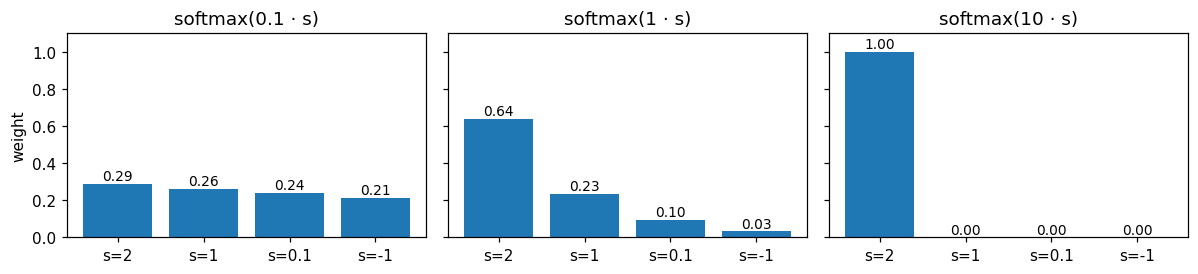

In [52]:
s = torch.tensor([2.0, 1.0, 0.1, -1.0])
fig, axes = plt.subplots(1, 3, figsize=(11, 2.6), sharey=True)
for ax, c in zip(axes, [0.1, 1.0, 10.0]):
    w = softmax(c * s)
    ax.bar(range(4), w)
    ax.set_xticks(range(4), [f"s={v:g}" for v in s.tolist()])
    ax.set_title(f"softmax({c:g} · s)")
    for i, v in enumerate(w):
        ax.text(i, v.item() + 0.02, f"{v.item():.2f}", ha="center", fontsize=9)
axes[0].set_ylabel("weight")
axes[0].set_ylim(0, 1.1)
plt.tight_layout()

### 1.3 Why divide by $\sqrt{d_k}$?

Slide 35 claims: if the entries of $q$ and $k$ are independent with mean 0 and variance 1, then the dot product
$q \cdot k$ has **variance $d_k$**. Verify this empirically: for each $d_k$, draw 20 000 random pairs $(q, k)$,
compute their dot products and the variance of those 20 000 numbers.

In [87]:
for d_k in [4, 16, 64, 256]:
    q = torch.randn(20_000, d_k)  # 20 000 queries, one per row
    k = torch.randn(20_000, d_k)  # 20 000 keys

    print(q[-1].shape)
    print(q[:,-1].shape)

torch.Size([4])
torch.Size([20000])
torch.Size([16])
torch.Size([20000])
torch.Size([64])
torch.Size([20000])
torch.Size([256])
torch.Size([20000])


In [90]:
variances = {}
for d_k in [4, 16, 64, 256]:
    q = torch.randn(20_000, d_k)  # 20 000 queries, one per row
    k = torch.randn(20_000, d_k)  # 20 000 keys
    variances[d_k] = torch.var(q[:,-1] * k[:,-1])
    print(f"d_k = {d_k:4d}   Var(q·k) = {variances[d_k]:7.2f}")

check_dot_product_variance(variances)

d_k =    4   Var(q·k) =    1.02
d_k =   16   Var(q·k) =    1.01
d_k =   64   Var(q·k) =    1.01
d_k =  256   Var(q·k) =    1.00


CheckFailed: ❌ Var(q·k): for d_k = 4 you measured Var(q·k) = 1.02. Did you take the dot product over the last dimension (one scalar per pair)?
   📖 Revisit slide 35 – Why Divide by √d_k?.

What does this do to attention? Below, one random query is compared with 16 random keys, and we record the
**largest** of the 16 attention weights (averaged over 500 repetitions). A value of $1/16$ means uniform weights,
a value of $1$ means one-hot. Just run the cell.

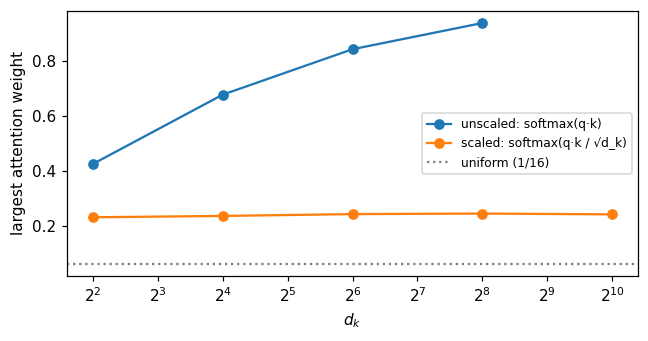

In [74]:
dims = [4, 16, 64, 256, 1024]
max_weight = {"unscaled: softmax(q·k)": [], "scaled: softmax(q·k / √d_k)": []}
for d_k in dims:
    q, K = torch.randn(500, 1, d_k), torch.randn(500, 16, d_k)
    scores = (q @ K.transpose(-2, -1)).squeeze(1)  # (500, 16)
    max_weight["unscaled: softmax(q·k)"].append(softmax(scores).amax(-1).mean().item())
    max_weight["scaled: softmax(q·k / √d_k)"].append(softmax(scores / math.sqrt(d_k)).amax(-1).mean().item())

plt.figure(figsize=(6, 3.2))
for label, values in max_weight.items():
    plt.plot(dims, values, "o-", label=label)
plt.axhline(1 / 16, color="gray", ls=":", label="uniform (1/16)")
plt.xscale("log", base=2)
plt.xlabel("$d_k$")
plt.ylabel("largest attention weight")
plt.legend(fontsize=8)
plt.tight_layout()

✍️ **Question 1.** Without the scaling, attention becomes almost one-hot for large $d_k$. Why is this a problem
for **training**, not only for the forward pass? *Hint:* think about the gradient of a saturated softmax (slide 35).

> ✍️ *Your answer:* …

---
## 2 · Scaled dot-product attention ⏱ ~15 min

📖 Slides 26–34, in particular slide 30 – *Why Attention Needs Parameters*, slide 31 – *Why Three Matrices?* and
slide 34 – *Scaled Dot-Product Attention*

### 2.1 Attention without parameters

The first version on slide 28 has no learnable parameter at all: scores $XX^\top$, then a row-wise softmax,
$A = \operatorname{softmax}(XX^\top)$. Compute $A$ for toy embeddings of the running example *"The dog ate his dinner"*.

In [78]:
X = torch.randn(5, 8, generator=torch.Generator().manual_seed(7))  # toy embeddings, one token per row
softmax(X@X.T)

tensor([[0.670, 0.000, 0.173, 0.001, 0.155],
        [0.000, 0.998, 0.000, 0.000, 0.001],
        [0.006, 0.000, 0.976, 0.001, 0.017],
        [0.000, 0.000, 0.000, 1.000, 0.000],
        [0.096, 0.001, 0.327, 0.000, 0.575]])

In [105]:
tokens = ["The", "dog", "ate", "his", "dinner"]

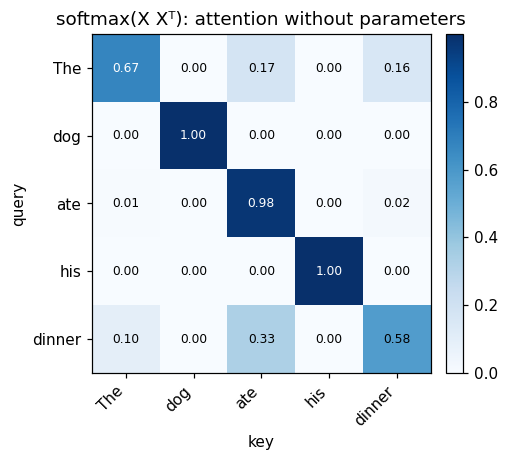

In [96]:
tokens = ["The", "dog", "ate", "his", "dinner"]
X = torch.randn(5, 8, generator=torch.Generator().manual_seed(7))  # toy embeddings, one token per row

A = softmax(X@X.T)


assert A.shape == (5, 5) and torch.allclose(A.sum(-1), torch.ones(5)), "A should be 5 x 5 with rows summing to 1"
plot_attention(A, tokens, tokens, title="softmax(X Xᵀ): attention without parameters");

✍️ **Question 2.** Slide 30 lists three reasons why this parameter-free version is not enough. Which one can you
**see** in the heatmap, and why does it happen?

> ✍️ *Your answer:* …

### 2.2 Implement scaled dot-product attention

$$\operatorname{Attention}(Q, K, V) = \operatorname{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}} + M\right) V$$

| Step | Operation (slide 34) |
|---|---|
| 1 Scores | $QK^\top$: dot product of every query with every key |
| 2 Scale | divide by $\sqrt{d_k}$ |
| 3 Mask (optional) | add $M$: $0$ for allowed, $-\infty$ for blocked positions |
| 4 Softmax | over the **keys**, so that every row sums to 1 |
| 5 Weight | weighted sum of the values |

Your function must work for any number of leading batch dimensions, e.g. `(B, h, n, d_k)` later for multi-head
attention. Use `K.transpose(-2, -1)` (not `K.T`) and `@`, which both respect batch dimensions. Use your own `softmax`.

In [95]:
def scaled_dot_product_attention(Q, K, V, mask=None):
    """
    Q: (..., n_q, d_k)   K: (..., n_k, d_k)   V: (..., n_k, d_v)
    mask: None, or an additive float mask broadcastable to (..., n_q, n_k): 0 = allowed, -inf = blocked
    Returns (output, weights) with shapes (..., n_q, d_v) and (..., n_q, n_k).
    """
    d_k = Q.shape[-1]

    return torch.softmax( (Q @ K.T) / torch.sqrt(d_k) ) @ V


check_attention(scaled_dot_product_attention)

CheckFailed: ❌ scaled_dot_product_attention: your code raised RuntimeError: The size of tensor a (3) must match the size of tensor b (6) at non-singleton dimension 1
   📖 Revisit slide 34 – Scaled Dot-Product Attention.

### 2.3 Why three matrices?

Slide 31 first tries a **single** learnable matrix $U$, which gives the scores $XU\,(XU)^\top = XUU^\top X^\top$.
With separate projections we get $Q K^\top = XW_Q\,(XW_K)^\top$ instead. Compute both score matrices for the toy
embeddings `X` from 2.1 and find out which of them is symmetric.

In [104]:
torch.manual_seed(0)
U, W_Q, W_K = torch.randn(8, 4), torch.randn(8, 4), torch.randn(8, 4)

S_single = X @ U @ U.T @ X.T
S_qk = X @ W_Q @ (X @ W_K).T
print("X U Uᵀ Xᵀ symmetric?", torch.allclose(S_single, S_single.T))
print("Q Kᵀ      symmetric?", torch.allclose(S_qk, S_qk.T))

X U Uᵀ Xᵀ symmetric? True
Q Kᵀ      symmetric? False


✍️ **Question 3.** Slide 31 gives two reasons for separate $W_Q$, $W_K$ and $W_V$. Name both, and use the
*chisel → tool* example to explain why a symmetric score matrix is a problem.

> ✍️ *Your answer:* …

---
## 3 · Masks ⏱ ~8 min

📖 Slide 36 – *Masking: What a Token Must Not See*, slide 65 – *Inside a Decoder Layer*

A mask is **added to the scores** before the softmax. Since $e^{-\infty} = 0$, blocked positions get weight
exactly 0 and the remaining weights still sum to 1.

- **Causal mask** (decoder): query $i$ may only see keys $j \le i$, so a token cannot read the word it has to predict.
- **Padding mask**: sequences in a batch are padded to the same length with `[PAD]`; no query may attend to those.

*Hints:* `torch.triu`, `torch.arange`, `Tensor.masked_fill`.

In [ ]:
def causal_mask(n):
    """(n, n) additive mask: 0 where key j <= query i, -inf where j > i (the future)."""
    raise NotImplementedError  # TODO: your code here


check_causal_mask(causal_mask)
print(causal_mask(5))

In [ ]:
def padding_mask(lengths, n):
    """
    lengths: (B,) number of real tokens in each sequence; the rest is [PAD].
    Returns a (B, 1, n) additive mask: -inf at key positions >= length, 0 elsewhere.
    The middle dimension of size 1 broadcasts over all queries.
    """
    raise NotImplementedError  # TODO: your code here


check_padding_mask(padding_mask)

Masks are just additive matrices, so they **combine by addition** (with broadcasting). Here is the tokenized
sentence from slide 15, padded to length 8, once with the padding mask alone and once combined with the causal mask:

In [ ]:
words = ["this", "teddy", "bear", "is", "[UNK]", "cute", "[PAD]", "[PAD]"]
torch.manual_seed(1)
Q = K = V = torch.randn(1, 8, 4)
M_pad = padding_mask(torch.tensor([6]), 8)  # (1, 1, 8)
M_both = M_pad + causal_mask(8)  # (1, 1, 8) + (8, 8) -> (1, 8, 8)
_, w_pad = scaled_dot_product_attention(Q, K, V, M_pad)
_, w_both = scaled_dot_product_attention(Q, K, V, M_both)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
plot_attention(w_pad[0], words, words, "padding mask", ax=axes[0])
plot_attention(w_both[0], words, words, "padding + causal mask", ax=axes[1])
plt.tight_layout()

🧠 **Predict:** what does the softmax return for a row in which **every** position is masked, i.e. all scores are
$-\infty$? Write down your guess, then run the cell.

> ✍️ *Your answer:* …

In [ ]:
print(softmax(torch.full((1, 4), float("-inf"))))

---
## 4 · Multi-head attention ⏱ ~10 min

> 🔜 **Ahead of the lecture.** Multi-head attention is covered in the next lecture. You do not need the slides for this
> section: everything you need is explained here. The slide numbers are for looking it up later.

📖 Slide 42 – *Why Multiple Heads?*, slide 43 – *The Original Architecture*, slide 44 – *Shapes and Parameters*

**Why several heads?** One row of attention weights is one softmax, so it can follow only one kind of relation
sharply. A token usually has several questions at once: in *"The animal didn't cross the street because it was
too tired"*, the token *it* needs to know what it refers to (*animal*) and what is said about it (*tired*).
Multi-head attention therefore runs $h$ attention layers ("heads") in parallel, each with its own $W_Q$, $W_K$,
$W_V$. Each head works in a smaller space of size $d_k = d / h$, so all heads together cost about as much as one
full-size head. The head outputs are concatenated and mixed by a final projection $W_O$:

$$\operatorname{MHA}(X) = \operatorname{Concat}(\text{head}_1, \dots, \text{head}_h)\,W_O, \qquad
  \text{head}_j = \operatorname{Attention}\big(XW_Q^{(j)},\ XW_K^{(j)},\ XW_V^{(j)}\big).$$

| Stage | Operation (slide 43) |
|---|---|
| Linear | project $Q$, $K$, $V$ with learned matrices |
| Split | divide into $h$ heads, each of size $d_k = d / h$ |
| Attention | scaled dot-product attention in every head, in parallel |
| Concat + Linear | join the heads and mix them with $W_O$ |

**Implementation trick.** Instead of $h$ small projections we use **one** `nn.Linear(d, d)` each for Q, K and V:
the columns $j \cdot d_k, \dots, (j+1) \cdot d_k - 1$ of its output belong to head $j$. *Split* then is a reshape
`(B, n, d) → (B, n, h, d_k)` followed by a transpose to `(B, h, n, d_k)`. Now the heads are just another batch
dimension, and your `scaled_dot_product_attention` processes all of them in parallel. `split_heads` and
`merge_heads` are given: read them, then implement `forward`.

*Hint:* after `transpose` a tensor is no longer contiguous in memory, so use `reshape` instead of `view` there.

In [ ]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        self.h, self.d_k = n_heads, d_model // n_heads
        self.w_q = nn.Linear(d_model, d_model)  # all heads at once
        self.w_k = nn.Linear(d_model, d_model)
        self.w_v = nn.Linear(d_model, d_model)
        self.w_o = nn.Linear(d_model, d_model)

    def split_heads(self, x):
        """(B, n, d_model) -> (B, h, n, d_k)"""
        B, n, _ = x.shape
        return x.view(B, n, self.h, self.d_k).transpose(1, 2)

    def merge_heads(self, x):
        """(B, h, n, d_k) -> (B, n, d_model), the 'Concat' step"""
        B, _, n, _ = x.shape
        return x.transpose(1, 2).reshape(B, n, self.h * self.d_k)  # reshape: not contiguous

    def forward(self, x, mask=None):
        """
        x: (B, n, d_model). mask: additive, of shape (n, n) or (B, 1, n) or (B, n, n).
        Returns output (B, n, d_model) and attention weights (B, h, n, n).
        """
        if mask is not None and mask.dim() == 3:
            mask = mask.unsqueeze(1)  # (B, ., n) -> (B, 1, ., n): the same mask for every head
        raise NotImplementedError  # TODO: your code here


check_mha(MultiHeadAttention)

🧠 **Predict:** a layer with $d = 512$ has $h = 1$ head or $h = 8$ heads. Which one has more parameters?
Write down your guess, then count.

> ✍️ *Your answer:* …

In [ ]:
for h in [1, 8]:
    n_params = sum(p.numel() for p in MultiHeadAttention(512, h).parameters())
    print(f"h = {h}: {n_params:,} parameters")

✍️ **Question 4.** Why does multi-head attention need the output projection $W_O$ (slide 44)? Give two reasons.

> ✍️ *Your answer:* …

---
## 5 · Positional encoding ⏱ ~12 min

> 🔜 **Ahead of the lecture.** Positional encoding is covered in the next lecture. You do not need the slides for this
> section: everything you need is explained here. The slide numbers are for looking it up later.

📖 Slide 46 – *Attention Is Order-Blind*, slide 47 – *What a Positional Encoding Must Provide*,
slide 48 – *Sinusoidal Positional Encoding*, slide 50 – *Example of Positional Encoding (2)*,
slide 52 – *Intuition: A Clock with Many Hands*, slide 53 – *Why Sine and Cosine Together*

### 5.1 Attention is order-blind

Every part of an attention layer is shared across positions: the same $W_Q$, $W_K$, $W_V$ for every token, and the
scores only compare contents. Nothing in it knows *where* a token stands. Formally (slide 46): for a permutation
$P$, $\operatorname{MHA}(PX) = P\,\operatorname{MHA}(X)$. Shuffle the input
rows and the output rows shuffle in exactly the same way. **Test this with your own layer:** compare the output for
the shuffled input `x[:, perm]` with the shuffled output.

In [ ]:
torch.manual_seed(0)
mha = MultiHeadAttention(d_model=16, n_heads=4)
x = torch.randn(1, 6, 16)
perm = torch.randperm(6)

raise NotImplementedError  # TODO: your code here

print("MHA(P x) == P MHA(x)?", equivariant)
assert equivariant, "self-attention without positional information should be permutation-equivariant"

### 5.2 Sinusoidal positional encoding

Slide 48 (Vaswani et al. 2017, Bishop & Bishop Eq. 12.25): dimensions come in **pairs**; the even index holds the
sine, the odd index the cosine of the same angle,

$$r_{n,i} = \begin{cases} \sin\!\left(\dfrac{n}{L^{i/d}}\right) & i \text{ even,} \\[2ex] \cos\!\left(\dfrac{n}{L^{(i-1)/d}}\right) & i \text{ odd,} \end{cases} \qquad L = 10\,000,$$

where $n$ is the position and $i = 0, \dots, d - 1$ the index of the embedding dimension. Think of a clock with many
hands (slide 52): each pair (sine, cosine) is one hand turning at its own speed. Fast hands tell neighbouring
positions apart, slow hands distant ones, and only all hands together give a unique reading. Implement it, vectorised
(no Python loop over positions). *Hint:* `P[:, 0::2]` selects the even columns. The check also compares your
function with the worked example on slide 50 ($d = 4$).

In [ ]:
def sinusoidal_pe(n_positions, d, L=10_000.0):
    """(n_positions, d) matrix; row n is the position vector r_n."""
    raise NotImplementedError  # TODO: your code here


check_sinusoidal_pe(sinusoidal_pe)

Your own version of the fingerprint from slide 51 (50 positions × 128 dimensions, the same settings as on the
slide), and the similarity of every pair of position vectors. Just run the cell.

In [ ]:
P = sinusoidal_pe(50, 128)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
im = axes[0].imshow(P, cmap="RdBu", aspect="auto", vmin=-1, vmax=1)
axes[0].set(title="sinusoidal fingerprint", xlabel="embedding dimension", ylabel="position n")
plt.colorbar(im, ax=axes[0])
im = axes[1].imshow(P @ P.T / 64, cmap="viridis")  # r_n · r_m, normalised: |r_n|^2 = 64
axes[1].set(title="similarity r_n · r_m / 64", xlabel="position m", ylabel="position n")
plt.colorbar(im, ax=axes[1])
plt.tight_layout()

✍️ **Question 5.** A positional encoding should meet four criteria (slide 47): *unique* (every position gets its
own vector), *bounded* (the values do not grow with the position, or they swamp the token embedding),
*extrapolating* (sequences longer than in training are still encoded sensibly) and *relative* (the offset between
two positions can be expressed independently of where they are).
(a) Which feature of the sinusoidal encoding provides each of them? Use both plots above.
(b) Why do the integer index $r_n = n$ and the normalised index $r_n = n / N$ fail?

> ✍️ *Your answer:* …

### 5.3 Position breaks the symmetry

Adding the position vectors to the tokens before the layer (slide 46: added, not concatenated) makes the same token
at a different position a different input. Repeat the test from 5.1 with positional encoding:

In [ ]:
pe = sinusoidal_pe(6, 16)
out, _ = mha(x + pe)
out_of_shuffled, _ = mha(x[:, perm] + pe)  # tokens shuffled, positions stay in place
print("still equivariant with PE?", torch.allclose(out_of_shuffled, out[:, perm], atol=1e-6))

---
## 6 · The Transformer block ⏱ ~8 min

> 🔜 **Ahead of the lecture.** The Transformer block is covered in the next lecture. You do not need the slides
> for this section: everything you need is explained here. The slide numbers are for looking it up later.

📖 Slide 55 – *The Transformer Layer*, slide 56 – *Skip (Residual) Connections*, slide 57 – *Layer Normalization*,
slide 59 – *Why a Feed-Forward Network?*

A block wraps the attention in three more ingredients:

- **Residual connection** $x + \operatorname{Sublayer}(x)$: the sublayer only learns the *change*, and gradients
  flow straight back through the identity path, so deep stacks still train.
- **Layer normalisation** $\operatorname{LN}$: normalises each token vector over its features to mean 0 and
  variance 1, then rescales it with learned parameters $\gamma$, $\beta$.
- **Feed-forward network (FFN)**: attention only *mixes* the tokens. A small MLP, applied to every token
  separately, adds a nonlinear transformation. It expands to $d_{ff} \approx 4d$ and compresses back.

Implement the **pre-norm** variant, the modern default (slide 55):

$$Z = X + \operatorname{MHA}(\operatorname{LN}_1(X)), \qquad \text{out} = Z + \operatorname{FFN}(\operatorname{LN}_2(Z)),$$

with $\operatorname{FFN}(x) = W_2\,\operatorname{GELU}(W_1 x + b_1) + b_2$ ("expand, detect, compress", slide 60).
All parts are already created in `__init__`. Remember that `self.attn(...)` returns `(output, weights)`;
**store the weights in `self.attn_weights`**, we visualise them in Section 7.

The post-norm branch (the original 2017 version, $Z = \operatorname{LN}_1(X + \operatorname{MHA}(X))$,
$\text{out} = \operatorname{LN}_2(Z + \operatorname{FFN}(Z))$) is optional and only used in stretch S4.

In [ ]:
class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, pre_norm=True):
        super().__init__()
        self.pre_norm = pre_norm
        self.attn = MultiHeadAttention(d_model, n_heads)
        self.ln1 = nn.LayerNorm(d_model)
        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model))
        self.attn_weights = None  # (B, h, n, n), filled in by forward

    def forward(self, x, mask=None):
        if self.pre_norm:
            raise NotImplementedError  # TODO: your code here
        else:  # optional, for stretch S4
            raise NotImplementedError  # TODO: your code here
        return x


check_block(TransformerBlock)

✍️ **Question 6** (if time is short, at home). Slide 59: "Attention mixes the inputs, it does not transform
them." Explain why the output of the attention sublayer always lies in the span of the value vectors, and what the
FFN adds.

> ✍️ *Your answer:* …

---
## 7 · Train a tiny Transformer: who sang this? ⏱ ~12 min

📖 Intro slide 19 – *Long, Structured Sequences*: "A species is not identified by one moment of a spectrogram. It is
identified by **which elements follow each other**, and at what distance."

**A toy world.** A recording is a sequence of 32 syllable tokens. Two of them matter: a `trill` and a `whistle`.
The other 30 are background: syllables of other birds, wind, rain, a passing car. Two species sing the same two
syllables, but in a different order:

- species 1: `trill` … `whistle` (label 1)
- species 0: `whistle` … `trill` (label 0)

The gap between the two syllables is random. Every recording contains **exactly one** trill and one whistle, so the
*bag of tokens* of both species looks the same. Only the order tells them apart.

In [ ]:
SYLLABLES = ["trill", "whistle", "chirp", "tsip", "buzz", "rattle", "peep", "wind", "rain", "car", "click", "hum"]
TRILL, WHISTLE = 0, 1


def make_recordings(n_recordings, length=32, seed=0):
    """Token ids (n_recordings, length) and labels (n_recordings,): 1 if the trill comes before the whistle."""
    g = torch.Generator().manual_seed(seed)
    x = torch.randint(2, len(SYLLABLES), (n_recordings, length), generator=g)  # background
    where = torch.stack([torch.randperm(length, generator=g)[:2] for _ in range(n_recordings)])
    rows = torch.arange(n_recordings)
    x[rows, where[:, 0]] = TRILL
    x[rows, where[:, 1]] = WHISTLE
    y = (where[:, 0] < where[:, 1]).long()
    return x, y


x_train, y_train = make_recordings(4000, seed=0)
x_test, y_test = make_recordings(1000, seed=1)
for i in range(3):
    print(f"label {y_train[i].item()}:", " ".join(SYLLABLES[t] for t in x_train[i, :16]), "...")

### 7.1 The model

Put your pieces together. `forward` takes token ids of shape `(B, n)` and returns logits of shape `(B, 2)`:

1. look up the token embeddings, giving `(B, n, d)`;
2. if `self.use_pe`: add the positional encoding of the first `n` positions;
3. run all blocks;
4. apply the final LayerNorm (in a pre-norm stack the last block's output is not normalised);
5. average over the positions, giving one vector per recording;
6. apply the linear head.

In [ ]:
class BirdSongClassifier(nn.Module):
    def __init__(self, vocab_size, d_model=32, n_heads=4, d_ff=64, n_layers=2, max_len=64, use_pe=True, pre_norm=True):
        super().__init__()
        self.use_pe = use_pe
        self.embed = nn.Embedding(vocab_size, d_model)
        self.register_buffer("pe", sinusoidal_pe(max_len, d_model))  # (max_len, d_model), not trained
        self.blocks = nn.ModuleList([TransformerBlock(d_model, n_heads, d_ff, pre_norm) for _ in range(n_layers)])
        self.ln_final = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, 2)

    def forward(self, x):
        raise NotImplementedError  # TODO: your code here


check_classifier(BirdSongClassifier)

### 7.2 Training

The training loop is given. 🧠 **Predict first:** we train one model **with** and one **without** positional
encoding. What test accuracy do you expect for each? Write down your guess, then run the cell (about 20–40 s on Colab).

> ✍️ *Your answer:* …

In [ ]:
def accuracy(model, x, y):
    model.eval()
    with torch.no_grad():
        return (model(x).argmax(-1) == y).float().mean().item()


def train(model, epochs=10, lr=3e-3, batch_size=64, seed=0, verbose=True):
    torch.manual_seed(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    history = []
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(len(x_train))
        for i in range(0, len(x_train), batch_size):
            idx = perm[i : i + batch_size]
            loss = F.cross_entropy(model(x_train[idx]), y_train[idx])
            opt.zero_grad()
            loss.backward()
            opt.step()
        history.append(accuracy(model, x_test, y_test))
        if verbose:
            print(f"  epoch {epoch + 1:2d}   loss {loss.item():.3f}   test accuracy {history[-1]:.3f}")
    return history


histories = {}
for use_pe in [True, False]:
    print(f"use_pe = {use_pe}")
    torch.manual_seed(0)
    model = BirdSongClassifier(len(SYLLABLES), use_pe=use_pe)
    t0 = time.time()
    histories[use_pe] = train(model)
    print(f"  ({time.time() - t0:.0f} s)")
    if use_pe:
        model_pe = model  # keep the trained model for 7.3

plt.figure(figsize=(6, 3.2))
for use_pe, h in histories.items():
    plt.plot(range(1, len(h) + 1), h, "o-", label=f"use_pe = {use_pe}")
plt.axhline(0.5, color="gray", ls=":", label="chance")
plt.xlabel("epoch")
plt.ylabel("test accuracy")
plt.ylim(0.4, 1.02)
plt.legend()
plt.tight_layout()

✍️ **Question 7.** Explain why the model **without** positional encoding cannot do better than 50 %, no matter how
long it trains. Use what you showed in Section 5.1.

> ✍️ *Your answer:* …

### 7.3 What did the model learn to look at?

The heatmaps show the attention weights of the first block for one test recording, one per head. Look at the rows
of the `trill` and `whistle` queries. Just run the cell.

In [ ]:
i = 0
model_pe.eval()
with torch.no_grad():
    model_pe(x_test[i : i + 1])
weights = model_pe.blocks[0].attn_weights[0]  # (h, n, n)
labels = [SYLLABLES[t] for t in x_test[i]]
special = [j for j, t in enumerate(x_test[i]) if t in (TRILL, WHISTLE)]
print(f"label {y_test[i].item()}: trill at position {labels.index('trill')}, whistle at position {labels.index('whistle')}")

fig, axes = plt.subplots(1, weights.shape[0], figsize=(4 * weights.shape[0], 4))
for head, ax in enumerate(axes):
    ax.imshow(weights[head], cmap="Blues")
    ax.set_title(f"block 1, head {head + 1}")
    ax.set_yticks(special, [f"{labels[j]} ({j})" for j in special])
    ax.set_xticks(special, [f"{labels[j]} ({j})" for j in special], rotation=90)
    ax.set_xlabel("key")
plt.tight_layout()

✍️ **Question 8.** Describe what at least one head does with the `trill` or `whistle` query. How does this help to
decide the order? Is attention alone enough, or does the model need the positional encoding as well?

> ✍️ *Your answer:* …

---
## Wrap-up

| You built | Slides |
|---|---|
| a numerically stable softmax and saw why scores are divided by $\sqrt{d_k}$ | 27, 35 |
| scaled dot-product attention, and why it needs $W_Q \neq W_K$ and $W_V$ | 30–34 |
| causal and padding masks as additive matrices | 36, 65 |
| multi-head attention with the heads as a batch dimension | 42–44 |
| sinusoidal positional encoding, and saw attention lose its order-blindness | 46–53 |
| a pre-norm Transformer block, identical to `nn.TransformerEncoderLayer` | 55–60 |
| a tiny encoder-only Transformer that solves a task no position-blind model can | 66, Intro 19 |

**Next week (ViT):** the block stays exactly as you built it. Only the tokenizer changes: an image is cut into
patches, and each patch becomes a token.

---
## ⭐ Stretch tasks (optional, at home)

Independent of each other; pick what interests you.

- **S1** Relative positions: the rotation behind sinusoidal PE, and RoPE (slide 53)
- **S2** Why the FFN expands first (slide 61)
- **S3** Real attention: contextual embeddings and attention heads in DistilBERT (slides 18, 25)
- **S4** Ablations: pre-norm vs. post-norm and longer sequences than in training (slides 47, 57)

---
### ⭐ S1 · Relative positions: rotation and RoPE

📖 Slide 53 – *Why Sine and Cosine Together*. The slide only mentions RoPE in one sentence; S1.2 shows how it
works. Most current language models use it instead of the sinusoidal encoding. Source: Su et al. (2021),
*RoFormer: Enhanced Transformer with Rotary Position Embedding*.

**S1.1 The rotation.** Take one pair $(r_{n,i}, r_{n,i+1}) = (\sin n\omega_i, \cos n\omega_i)$, $i$ even, with
the frequency $\omega_i = 1 / L^{i/d}$ (slide 53). The addition theorems give

$$\begin{pmatrix} \sin (n+k)\omega_i \\ \cos (n+k)\omega_i \end{pmatrix}
  = R(k\omega_i) \begin{pmatrix} \sin n\omega_i \\ \cos n\omega_i \end{pmatrix}
  \qquad\text{with}\qquad R(\theta) = \begin{pmatrix} \cos\theta & \sin\theta \\ -\sin\theta & \cos\theta \end{pmatrix}.$$

Verify numerically that one fixed matrix $R(k\omega_i)$ maps **every** position $n$ to $n + k$.

In [ ]:
d, L, k, i = 16, 10_000.0, 3, 4  # i: the even dimension that starts the pair
P = sinusoidal_pe(100, d)
pair = P[:, i : i + 2]  # (100, 2): column 0 is the sine, column 1 the cosine
theta = k * L ** (-i / d)

raise NotImplementedError  # TODO: your code here

print("R(kω) · r_n == r_(n+k) for all n?", torch.allclose(shifted, pair[k:], atol=1e-5))

**S1.2 RoPE.** RoPE takes this rotation and applies it to the queries and keys instead of adding anything to the
input (slide 53: "RoPE later applies exactly this rotation to Q and K"). Each pair $(x_i, x_{i+1})$, $i$ even, of
a vector at position $p$ is rotated by the angle $p\,\omega_i$:

$$x'_i = x_i\cos p\omega_i - x_{i+1}\sin p\omega_i, \qquad x'_{i+1} = x_i\sin p\omega_i + x_{i+1}\cos p\omega_i.$$

Since queries and keys are both rotated, $q'_m \cdot k'_n$ depends only on the offset $m - n$.

In [ ]:
def apply_rope(x, positions, L=10_000.0):
    """x: (..., n, d) with d even, positions: (n,). Rotates pair (i, i+1), i even, at position p by p * L^(-i/d)."""
    d = x.shape[-1]
    raise NotImplementedError  # TODO: your code here


check_rope(apply_rope)

The score between the same $q$ and $k$, placed at positions $m$ and $n$, as a function of $m$ and $n$:
constant along every diagonal, so it depends only on $m - n$.

In [ ]:
torch.manual_seed(0)
q, k = torch.randn(1, 32), torch.randn(1, 32)
pos = torch.arange(40)
S = apply_rope(q.expand(40, 32), pos) @ apply_rope(k.expand(40, 32), pos).T
plt.imshow(S, cmap="RdBu")
plt.xlabel("key position n")
plt.ylabel("query position m")
plt.title("q'_m · k'_n with RoPE")
plt.colorbar();

✍️ **Question S1.** Relative encodings such as RoPE usually generalise better to sequences longer than those
seen in training. Explain why, using what you just implemented.

> ✍️ *Your answer:* …

---
### ⭐ S2 · Why the FFN expands first

📖 Slide 60 – *Expand, Detect, Compress*, slide 61 – *Illustration: Why Expand First?*

The toy task from slide 61: class A lies inside the square $|x_1|, |x_2| < 1$, class B outside. No straight line
separates them. Slide 61 solves it by hand with four detectors $h = \operatorname{ReLU}(x_1 - 1)$,
$\operatorname{ReLU}(-x_1 - 1)$, $\operatorname{ReLU}(x_2 - 1)$, $\operatorname{ReLU}(-x_2 - 1)$ and the read-out
$y = h_1 + h_2 + h_3 + h_4 - 0.1$. Train a linear classifier and a tiny FFN $2 \to 4 \to 1$ with ReLU, and compare
the four hidden units it learned (the "border detectors") with the hand-made ones.

In [ ]:
g = torch.Generator().manual_seed(0)
inside = 1.8 * torch.rand(300, 2, generator=g) - 0.9  # A: |x1|, |x2| < 0.9
outside = 5.0 * torch.rand(3000, 2, generator=g) - 2.5
outside = outside[outside.abs().max(dim=1).values > 1.3][:300]  # B: outside the square, with a small margin
pts = torch.cat([inside, outside])
labels_ab = torch.cat([torch.zeros(300), torch.ones(300)])  # 0 = A, 1 = B

slide_ffn = nn.Sequential(nn.Linear(2, 4), nn.ReLU(), nn.Linear(4, 1))  # the hand-made weights from slide 61
with torch.no_grad():
    slide_ffn[0].weight.copy_(torch.tensor([[1.0, 0.0], [-1.0, 0.0], [0.0, 1.0], [0.0, -1.0]]))
    slide_ffn[0].bias.fill_(-1.0)
    slide_ffn[2].weight.fill_(1.0)
    slide_ffn[2].bias.fill_(-0.1)

linear = nn.Linear(2, 1)
torch.manual_seed(0)  # if your FFN gets stuck below ~95 %, a ReLU unit "died": try another seed
raise NotImplementedError  # TODO: your code here

for net in [linear, ffn]:
    opt = torch.optim.Adam(net.parameters(), lr=0.05)
    for step in range(1500):
        loss = F.binary_cross_entropy_with_logits(net(pts).squeeze(-1), labels_ab)
        opt.zero_grad()
        loss.backward()
        opt.step()
nets = [("linear", linear), ("FFN 2 → 4 → 1, trained", ffn), ("FFN from slide 61", slide_ffn)]
for name, net in nets:
    acc = ((net(pts).squeeze(-1) > 0).float() == labels_ab).float().mean().item()
    print(f"{name:24s} accuracy {acc:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
grid = torch.stack(torch.meshgrid(torch.linspace(-3, 3, 200), torch.linspace(-3, 3, 200), indexing="xy"), -1)
t = torch.linspace(-3, 3, 2)
for ax, (name, net) in zip(axes, nets):
    with torch.no_grad():
        ax.contourf(grid[..., 0], grid[..., 1], net(grid).squeeze(-1) > 0, alpha=0.2, cmap="coolwarm")
    ax.scatter(*pts.T, c=labels_ab, cmap="coolwarm", s=6)
    ax.set_title(name)
    ax.set_aspect("equal")
    ax.set(xlim=(-3, 3), ylim=(-3, 3))
    if net is linear:
        continue
    w1, b1 = net[0].weight.detach(), net[0].bias.detach()
    for j in range(4):  # the line w_j · x + b_j = 0 is where detector j starts firing
        a, b = w1[j]
        if abs(b) > abs(a):
            ax.plot(t, -(a * t + b1[j]) / b, "k--", lw=1)
        else:
            ax.plot(-(b * t + b1[j]) / a, t, "k--", lw=1)
plt.tight_layout()

✍️ **Question S2.** What does each of the four hidden units detect (dashed lines)? How do the learned detectors
differ from the hand-made ones on slide 61, and why does it not matter? Why would a FFN of width 2 (no expansion)
struggle with this task?

> ✍️ *Your answer:* …

---
### ⭐ S3 · Real attention: DistilBERT

📖 Slide 18 – *One Fixed Vector Is Not Enough*, slide 25 – *Why It Helps: What Does "it" Refer To?*

Everything so far used toy data. Here we look inside a real pre-trained encoder, DistilBERT (a 6-layer BERT). The
cell downloads about 270 MB on first use.

In [ ]:
import warnings

from transformers import AutoModel, AutoTokenizer
from transformers.utils import logging as hf_logging

warnings.filterwarnings("ignore")  # keep the output readable (download progress, HF token hints)
hf_logging.set_verbosity_error()

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")
bert = AutoModel.from_pretrained("distilbert-base-uncased", attn_implementation="eager").eval()


def encode(sentence):
    """Token strings and the outputs (hidden states of all layers, attention of all layers)."""
    inputs = tokenizer(sentence, return_tensors="pt")
    with torch.no_grad():
        out = bert(**inputs, output_hidden_states=True, output_attentions=True)
    return tokenizer.convert_ids_to_tokens(inputs["input_ids"][0]), out

**S3.1 Contextual embeddings.** Compute the cosine similarity between the vectors of the word *bank* in the three
sentences, once for the **static** input embedding (`hidden_states[0]`, the lookup table) and once for the
**contextual** output of the last layer (`hidden_states[-1]`).

In [ ]:
sentences = ["he sat on the bank by the river", "she deposited money at the bank", "the river bank was muddy"]

static, contextual = [], []
for sentence in sentences:
    toks, out = encode(sentence)
    pos = toks.index("bank")
    static.append(out.hidden_states[0][0, pos])
    contextual.append(out.hidden_states[-1][0, pos])

raise NotImplementedError  # TODO: your code here

short = ["river (1)", "money", "river (2)"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
plot_attention(S_static, short, short, "static: input embedding", ax=axes[0])
plot_attention(S_contextual, short, short, "contextual: last layer", ax=axes[1])
plt.tight_layout()

*Note:* DistilBERT's `hidden_states[0]` already contains its learned **position** embedding, so the "static"
vectors differ slightly when *bank* sits at different positions. The word part is identical.

**S3.2 What does "it" attend to?** For the sentence from slide 25, the cell plots the attention of the query *it*
in every head of one layer. Change `layer` and look for heads that resolve the reference.

In [ ]:
toks, out = encode("The animal didn't cross the street because it was too tired.")
layer = 4  # 0 .. 5
att = out.attentions[layer][0, :, toks.index("it")]  # (heads, n): weights of the query "it"
plt.figure(figsize=(10, 4))
plt.imshow(att, cmap="Blues", aspect="auto")
plt.xticks(range(len(toks)), toks, rotation=60)
plt.yticks(range(att.shape[0]), [f"head {h + 1}" for h in range(att.shape[0])])
plt.title(f'layer {layer + 1}: attention of the query "it"')
plt.colorbar()
plt.tight_layout()

✍️ **Question S3.** (a) Interpret the two similarity matrices. (b) Real attention looks messier than the
illustration on slide 25. Many heads put much of their weight on `[CLS]`, `[SEP]` or punctuation. Why might a head
do that? *Hint:* the weights of a row must sum to 1.

> ✍️ *Your answer:* …

---
### ⭐ S4 · Ablations on the bird-song task

📖 Slide 47 – criterion 3 *Extrapolating*, slide 55 and slide 57 – pre-norm vs. post-norm

**S4.1 Longer recordings.** The model from Section 7 was trained on recordings of length 32. How does it do on
recordings of length 48 and 64, where trill and whistle can sit at positions it has never seen? 🧠 Predict first.

In [ ]:
for length in [32, 48, 64]:
    x_long, y_long = make_recordings(1000, length=length, seed=2)
    print(f"length {length}: test accuracy {accuracy(model_pe, x_long, y_long):.3f}")

**S4.2 Pre-norm vs. post-norm.** Implement the post-norm branch of `TransformerBlock` in Section 6 (and re-run that
cell), then check it and train both variants on a deeper model with a larger learning rate, where stability matters
more. 🧠 Predict first. (Runs for 1–3 minutes.)

In [ ]:
check_block(TransformerBlock, pre_norm=False)

results = {}
for pre_norm in [True, False]:
    accs = []
    for seed in range(3):
        torch.manual_seed(seed)
        m = BirdSongClassifier(len(SYLLABLES), n_layers=6, pre_norm=pre_norm)
        accs.append(train(m, epochs=5, lr=1e-2, seed=seed, verbose=False)[-1])
    results[pre_norm] = accs
    print(f"pre_norm = {pre_norm}: final test accuracy per seed {[f'{a:.2f}' for a in accs]}")

✍️ **Question S4.** (a) Which criterion from slide 47 does S4.1 test, and does the sinusoidal encoding meet it in
practice? (b) What do you observe in S4.2, and how does it relate to slide 57's remark that pre-norm "trains more
stably"?

> ✍️ *Your answer:* …